<a href="https://colab.research.google.com/github/Mohammadasfour0743/DD2360-GPU-Assignments/blob/main/Assignment2/Q2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%%writefile vectorAdd.cu
#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include <sys/time.h>


double cpuSecond()
{
   struct timeval tp;
   gettimeofday(&tp,NULL);
   return ((double)tp.tv_sec + (double)tp.tv_usec*1.e-6);
}

__global__ void vectorAddKernel( float *A, float *B, float *C, int N)
{
  int i = blockIdx.x * blockDim.x + threadIdx.x;

  if(i < N)
    {
      C[i] = A[i] + B[i];
    }
}

int main()
{
  srand(time(NULL));
  int N_values[10] = {10000, 50000, 100000, 250000, 500000, 1000000, 2500000, 5000000, 7500000, 10000000};
  printf("N, H2D_Time_s, Kernel_Time_s, D2H_Time_s\n");
  for (int t = 0; t < 10; t++)
  {
      int N = N_values[t];
      size_t size = N * sizeof(float);

    float *h_A = (float *)malloc(size);
    float *h_B = (float *)malloc(size);
    float *h_result = (float *)malloc(size);
  for(int i = 0; i < N; i++)
  {
    h_A[i] = float(rand()%100);
    h_B[i] = float(rand()%100);
  }
  for(int i = 0; i < N; i++)
  {
    h_result[i] = h_A[i] + h_B[i];
  }
  printf("CPU result = %f + %f = %f\n", h_A[0], h_B[0], h_result[0]);

// GPU setup

float *d_A, *d_B, *d_result;

cudaMalloc((void **)&d_A, size);
cudaMalloc((void **)&d_B, size);
cudaMalloc((void **)&d_result, size);

double start_H2D = cpuSecond();
cudaMemcpy(d_A, h_A, size, cudaMemcpyHostToDevice);
cudaMemcpy(d_B, h_B, size, cudaMemcpyHostToDevice);
double time_H2D = cpuSecond() - start_H2D;

int threads = 512;
int blocksPerGrid = (N + threads - 1) / threads;

double start_Kernel = cpuSecond();
vectorAddKernel<<<blocksPerGrid, threads>>>(d_A, d_B, d_result, N);
cudaDeviceSynchronize();
double time_Kernel = cpuSecond() - start_Kernel;

double start_D2H = cpuSecond();
cudaMemcpy(h_result, d_result, size, cudaMemcpyDeviceToHost);
double time_D2H = cpuSecond() - start_D2H;

printf("%d, %f, %f, %f\n", N, time_H2D, time_Kernel, time_D2H);

printf("GPU result: %f + %f = %f\n", h_A[0], h_B[0], h_result[0]);

free(h_A);
free(h_B);
free(h_result);

cudaFree(d_A);
cudaFree(d_B);
cudaFree(d_result);
  }
return 0;
}


Writing vectorAdd.cu


In [ ]:
!nvcc vectorAdd.cu -o vectorAdd
!./vectorAdd

N, H2D_Time_s, Kernel_Time_s, D2H_Time_s
CPU result = 95.000000 + 16.000000 = 111.000000
10000, 0.000059, 0.000110, 0.000026
GPU result: 95.000000 + 16.000000 = 111.000000
CPU result = 34.000000 + 23.000000 = 57.000000
50000, 0.000113, 0.000029, 0.000065
GPU result: 34.000000 + 23.000000 = 57.000000
CPU result = 55.000000 + 15.000000 = 70.000000
100000, 0.000243, 0.000045, 0.000113
GPU result: 55.000000 + 15.000000 = 70.000000
CPU result = 38.000000 + 5.000000 = 43.000000
250000, 0.000597, 0.000102, 0.000304
GPU result: 38.000000 + 5.000000 = 43.000000
CPU result = 65.000000 + 60.000000 = 125.000000
500000, 0.000894, 0.000103, 0.000446
GPU result: 65.000000 + 60.000000 = 125.000000
CPU result = 2.000000 + 94.000000 = 96.000000
1000000, 0.001648, 0.000119, 0.000795
GPU result: 2.000000 + 94.000000 = 96.000000
CPU result = 78.000000 + 26.000000 = 104.000000
2500000, 0.004353, 0.000167, 0.002074
GPU result: 78.000000 + 26.000000 = 104.000000
CPU result = 72.000000 + 31.000000 = 103.000000

In [ ]:
!ncu ./vectorAdd

CPU result = 43.000000 + 77.000000 = 120.000000
==PROF== Connected to process 20401 (/content/vectorAdd)
==PROF== Profiling "vectorAddKernel" - 0: 0%....50%....100% - 9 passes
GPU result: 43.000000 + 77.000000 = 120.000000
==PROF== Disconnected from process 20401
[20401] vectorAdd@127.0.0.1
  vectorAddKernel(float *, float *, float *, int) (514, 1, 1)x(512, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- ------------
    Metric Name             Metric Unit Metric Value
    ----------------------- ----------- ------------
    DRAM Frequency                  Ghz         4.64
    SM Frequency                    Mhz       581.24
    Elapsed Cycles                cycle        7,964
    Memory Throughput                 %        63.91
    DRAM Throughput                   %        63.91
    Duration                         us        13.70
    L1/TEX Cache Throughput           %        28.40
    L2 Cache Throughpu

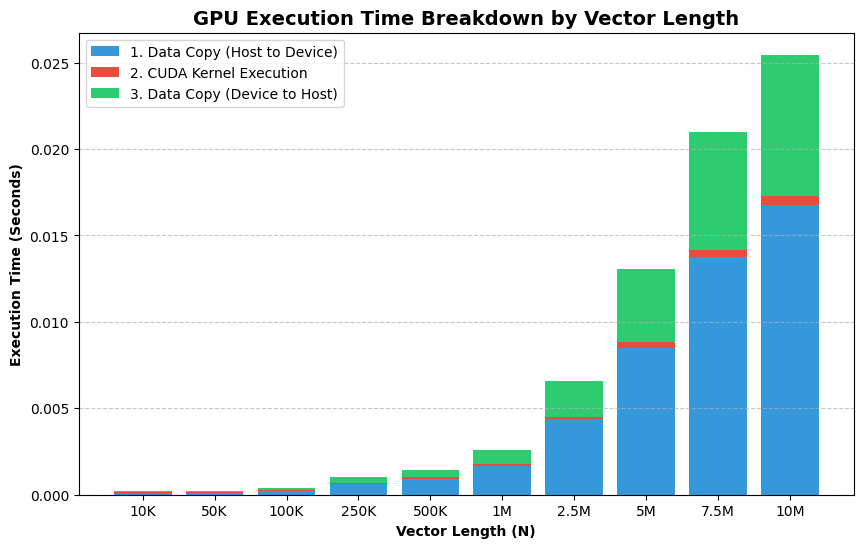

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

N_values = ['10K', '50K', '100K', '250K', '500K', '1M', '2.5M', '5M', '7.5M', '10M']
h2d_times = [0.000059, 0.000113, 0.000243, 0.000597, 0.000894, 0.001648, 0.004353, 0.008515, 0.013761, 0.016777]
kernel_times = [0.000110, 0.000029, 0.000045, 0.000102, 0.000103, 0.000119, 0.000167, 0.000309, 0.000394, 0.000528]
d2h_times = [0.000026, 0.000065, 0.000113, 0.000304, 0.000446, 0.000795, 0.002074, 0.004256, 0.006848, 0.008148]

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(N_values, h2d_times, label='1. Data Copy (Host to Device)', color='#3498db')
ax.bar(N_values, kernel_times, bottom=h2d_times, label='2. CUDA Kernel Execution', color='#e74c3c')

bottom_d2h = np.add(h2d_times, kernel_times)
ax.bar(N_values, d2h_times, bottom=bottom_d2h, label='3. Data Copy (Device to Host)', color='#2ecc71')

ax.set_xlabel('Vector Length (N)', fontweight='bold')
ax.set_ylabel('Execution Time (Seconds)', fontweight='bold')
ax.set_title('GPU Execution Time Breakdown by Vector Length', fontweight='bold', fontsize=14)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

# **Assignment** 2


In [ ]:
%%writefile tiled_gemm.cu

#include <stdio.h>
#include <stdlib.h>
#include <time.h>
#include <sys/time.h>
#include <math.h>

double cpuSecond() {
   struct timeval tp;
   gettimeofday(&tp,NULL);
   return ((double)tp.tv_sec + (double)tp.tv_usec*1.e-6);
}

void cpu_gemm(float *A, float *B, float *C, int m, int n, int k) {
  for(int i = 0; i < m; i++) {
    for(int j = 0; j < n; j++) {
      float sum = 0.0f;
      for(int l = 0; l < k; l++) {
        sum += A[i*k+l] * B[l*n+j];
      }
      C[i*n+j] = sum;
    }
  }
}

__global__ void gemm(float *A, float *B, float *C, int M, int N, int K) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < M && col < N) {
        float sum = 0.0f;
        for (int i = 0; i < K; ++i) {
            sum += A[row * K + i] * B[i * N + col];
        }
        C[row * N + col] = sum;
    }
}

__global__ void tiled_gemm(float *A, float *B, float *C, int M, int N, int K, int tileX, int tileY) {
  extern __shared__ float shared_mem[];
  float* As = shared_mem;
  float* Bs = &shared_mem[tileY * tileX];

  int bx = blockIdx.x;
  int by = blockIdx.y;
  int tx = threadIdx.x;
  int ty = threadIdx.y;

  int row = by * tileY + ty;
  int col = bx * tileX + tx;

  float sum = 0.0f;
  int numTiles = (K + tileX - 1) / tileX;
      for (int t = 0; t < numTiles; ++t) {
          if (row < M && (t * tileX + tx) < K)
              As[ty * tileX + tx] = A[row * K + t * tileX + tx];
          else
              As[ty * tileX + tx] = 0.0f;

          if (col < N && (t * tileX + ty) < K)
              Bs[ty * tileX + tx] = B[(t * tileX + ty) * N + col];
          else
              Bs[ty * tileX + tx] = 0.0f;

          __syncthreads();

          for (int i = 0; i < tileX; ++i) {
              sum += As[ty * tileX + i] * Bs[i * tileX + tx];
          }
          __syncthreads();
      }

      if (row < M && col < N) {
          C[row * N + col] = sum;
      }
}

bool checkResults(float *cpu, float *gpu, int size) {
    for (int i = 0; i < size; i++) {
        float expected = cpu[i];
        float actual = gpu[i];
        float diff = fabs(expected - actual);

        if (diff > 1e-2 && diff / (fabs(expected) + 1e-5) > 1e-3) {
            return false;
        }
    }
    return true;
}

int main(int argc, char **argv) {

    int M = 513, N = 1023, K = 8192;
    if (argc == 4) {
        M = atoi(argv[1]);
        N = atoi(argv[2]);
        K = atoi(argv[3]);
    }

    size_t sizeA = M * K * sizeof(float);
    size_t sizeB = K * N * sizeof(float);
    size_t sizeC = M * N * sizeof(float);

    float *h_A = (float *)malloc(sizeA);
    float *h_B = (float *)malloc(sizeB);
    float *h_C_cpu = (float *)malloc(sizeC);
    float *h_C_gpu = (float *)malloc(sizeC);

    for (int i = 0; i < M * K; i++) h_A[i] = (float)(rand() % 100) / 100.0f;
    for (int i = 0; i < K * N; i++) h_B[i] = (float)(rand() % 100) / 100.0f;

    float *d_A, *d_B, *d_C;
    cudaMalloc((void **)&d_A, sizeA);
    cudaMalloc((void **)&d_B, sizeB);
    cudaMalloc((void **)&d_C, sizeC);

    cudaMemcpy(d_A, h_A, sizeA, cudaMemcpyHostToDevice);
    cudaMemcpy(d_B, h_B, sizeB, cudaMemcpyHostToDevice);

    double start_cpu = cpuSecond();
    cpu_gemm(h_A, h_B, h_C_cpu, M, N, K);
    double time_cpu = cpuSecond() - start_cpu;
    printf("CPU Time: %f s\n", time_cpu);

    dim3 threads(16, 16);
    dim3 blocks((N + threads.x - 1) / threads.x, (M + threads.y - 1) / threads.y);

    double start_naive = cpuSecond();
    gemm<<<blocks, threads>>>(d_A, d_B, d_C, M, N, K);
    cudaDeviceSynchronize();
    double time_naive = cpuSecond() - start_naive;
    cudaMemcpy(h_C_gpu, d_C, sizeC, cudaMemcpyDeviceToHost);
    printf("Naive GEMM Time: %f s | Correct: %d\n", time_naive, checkResults(h_C_cpu, h_C_gpu, M*N));

    int tile_sizes[] = {8, 16, 32};
    for (int i = 0; i < 3; i++) {
        int tileX = tile_sizes[i];
        int tileY = tile_sizes[i];

        dim3 t_threads(tileX, tileY);
        dim3 t_blocks((N + t_threads.x - 1) / t_threads.x, (M + t_threads.y - 1) / t_threads.y);
        size_t shared_mem_size = 2 * tileX * tileY * sizeof(float);

        double start_tiled = cpuSecond();
        tiled_gemm<<<t_blocks, t_threads, shared_mem_size>>>(d_A, d_B, d_C, M, N, K, tileX, tileY);
        cudaDeviceSynchronize();
        double time_tiled = cpuSecond() - start_tiled;

        cudaMemcpy(h_C_gpu, d_C, sizeC, cudaMemcpyDeviceToHost);
        printf("Tiled GEMM (%dx%d) Time: %f s | Correct: %d\n", tileX, tileY, time_tiled, checkResults(h_C_cpu, h_C_gpu, M*N));
    }

    free(h_A); free(h_B); free(h_C_cpu); free(h_C_gpu);
    cudaFree(d_A); cudaFree(d_B); cudaFree(d_C);
    return 0;
}

Overwriting tiled_gemm.cu


In [ ]:
!nvcc tiled_gemm.cu -o tiled_gemm
!./tiled_gemm

CPU Time: 54.821331 s
Naive GEMM Time: 0.040050 s | Correct: 1
Tiled GEMM (8x8) Time: 0.043940 s | Correct: 1
Tiled GEMM (16x16) Time: 0.030748 s | Correct: 1
Tiled GEMM (32x32) Time: 0.031002 s | Correct: 1


In [ ]:
!ncu --set full ./tiled_gemm

==PROF== Connected to process 7599 (/content/tiled_gemm)
CPU Time: 76.138553 s
==PROF== Profiling "gemm" - 0: 0%....50%....100% - 33 passes
Naive GEMM Time: 12.695929 s | Correct: 0
==PROF== Profiling "tiled_gemm" - 1: 0%....50%....100% - 33 passes
Tiled GEMM (8x8) Time: 13.372867 s | Correct: 0
==PROF== Profiling "tiled_gemm" - 2: 0%....50%....100% - 33 passes
Tiled GEMM (16x16) Time: 11.569113 s | Correct: 0
==PROF== Profiling "tiled_gemm" - 3: 0%....50%....100% - 33 passes
Tiled GEMM (32x32) Time: 11.372881 s | Correct: 0
==PROF== Disconnected from process 7599
[7599] tiled_gemm@127.0.0.1
  gemm(float *, float *, float *, int, int, int) (64, 33, 1)x(16, 16, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: GPU Speed Of Light Throughput
    ----------------------- ----------- -------------
    Metric Name             Metric Unit  Metric Value
    ----------------------- ----------- -------------
    DRAM Frequency                  Ghz          4.98
    SM Frequency              

In [ ]:
!nvcc tiled_gemm.cu -o tiled_gemm

Running matrix size: 128x128...
Running matrix size: 256x256...
Running matrix size: 512x512...
Running matrix size: 768x768...
Running matrix size: 1024x1024...
Running matrix size: 1280x1280...
Running matrix size: 1536x1536...
Running matrix size: 2048x2048...


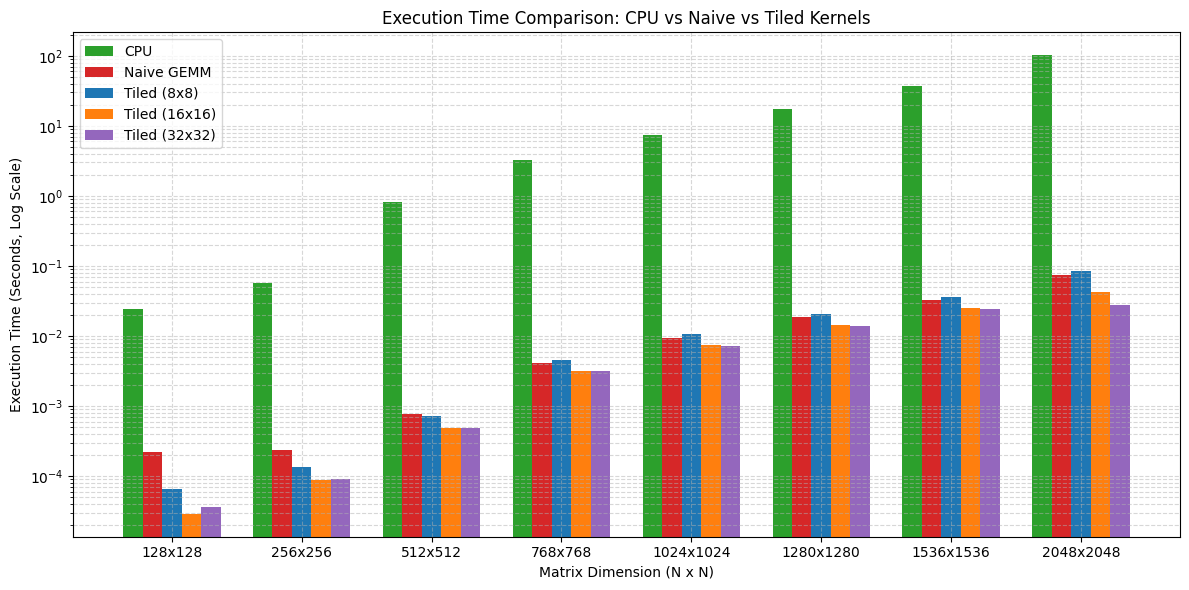

In [ ]:
import subprocess
import re
import matplotlib.pyplot as plt
import numpy as np

# We stop at 2048x2048 because CPU execution takes ~1 minute at that size.
sizes = [128, 256, 512, 768, 1024, 1280, 1536, 2048]
cpu_times = []
naive_times = []
t8_times = []
t16_times = []
t32_times = []

for size in sizes:
    print(f"Running matrix size: {size}x{size}...")
    # Calls the compiled CUDA program with M, N, K arguments
    result = subprocess.run(['./tiled_gemm', str(size), str(size), str(size)], capture_output=True, text=True)
    output = result.stdout

    # Extract times using regex
    cpu_times.append(float(re.search(r'CPU Time:\s+([0-9.]+)', output).group(1)))
    naive_times.append(float(re.search(r'Naive GEMM Time:\s+([0-9.]+)', output).group(1)))
    t8_times.append(float(re.search(r'Tiled GEMM \(8x8\) Time:\s+([0-9.]+)', output).group(1)))
    t16_times.append(float(re.search(r'Tiled GEMM \(16x16\) Time:\s+([0-9.]+)', output).group(1)))
    t32_times.append(float(re.search(r'Tiled GEMM \(32x32\) Time:\s+([0-9.]+)', output).group(1)))

# Generate Grouped Bar Chart
x = np.arange(len(sizes))
width = 0.15

fig, ax = plt.subplots(figsize=(12, 6))

# Plot bars
ax.bar(x - 2*width, cpu_times, width, label='CPU', color='#2ca02c')
ax.bar(x - width, naive_times, width, label='Naive GEMM', color='#d62728')
ax.bar(x, t8_times, width, label='Tiled (8x8)', color='#1f77b4')
ax.bar(x + width, t16_times, width, label='Tiled (16x16)', color='#ff7f0e')
ax.bar(x + 2*width, t32_times, width, label='Tiled (32x32)', color='#9467bd')

# Formatting
ax.set_ylabel('Execution Time (Seconds, Log Scale)')
ax.set_xlabel('Matrix Dimension (N x N)')
ax.set_title('Execution Time Comparison: CPU vs Naive vs Tiled Kernels')
ax.set_xticks(x)
ax.set_xticklabels([f"{s}x{s}" for s in sizes])
ax.legend()

# A Log scale is crucial here. Without it, the GPU bars will be invisible compared to the massive CPU times.
plt.yscale('log')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()

# Display the plot
plt.show()